# 2.5a Xử lý ảnh cho 2 vấn đề EDA: **nhiễu Gauss** và **tương phản tổn thương–da thấp**

Notebook theo khuôn: vấn đề → bằng chứng EDA → giả thuyết (viết trước khi đo) → phương pháp + tham số + lý do
→ đánh giá ảnh trước/sau (CPU, không CNN) → thí nghiệm CNN (sàng lọc trên val → 3 seed) → so sánh baseline → nhận xét.

**Phạm vi chương học phần:** Chương 3 (lọc trung bình, trung bình có trọng số/Gauss, trung vị; giãn tương phản
từng đoạn; cân bằng lược đồ xám; CLAHE – đề bài `DoAn_XuLyAnh.pdf` xếp CLAHE vào Ch.3, slide Ch.3 chỉ dạy bản toàn cục)
và Chương 4 (HSV tách cường độ khỏi màu → xử lý trên kênh độ sáng để giữ màu; L\*a\*b\* là mở rộng của ý này, không có trong slide).

**Quy tắc chống rò rỉ ở giai đoạn 1:** mọi so sánh tham số chỉ dùng ảnh thuộc `train_fit`; val/test không được nhìn.
Mọi phép xử lý chỉ dùng thống kê của chính ảnh đó (không có tham số học từ tập dữ liệu), áp dụng ở 600×450, trước
resize 224 và `ToTensor/Normalize`, giống nhau cho train/val/test.

Code: `src/preprocess/{noise,contrast}.py` (hàm xử lý), `src/preprocess/image_metrics.py` (đo), `src/preprocess/figures.py` (hình).
Kết quả: `outputs/preprocess/`, hình: `outputs/figures/preprocess/`.

In [1]:
import os, sys
from pathlib import Path
if not Path("archive").exists() and Path("../archive").exists():
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.preprocess import NOISE_CANDIDATES, CONTRAST_CANDIDATES, get_preprocess
from src.preprocess import image_metrics as IM
from src.preprocess import figures as F
from src.eda.plots import setup_style

setup_style()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
OUT = Path("outputs/preprocess"); OUT.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False   # True: đo lại image_metrics_*.csv (~1–2 phút/nhóm với 12 tiến trình)
N_JOBS = 12

q = pd.read_csv("outputs/eda/quality_metrics.csv")
flags = pd.read_csv("outputs/eda/image_flags.csv")
rules = pd.read_csv("outputs/eda/table_flag_rules.csv").set_index("key")
paths = q.set_index("image_id")["path"].to_dict()
qf = q.merge(flags[["image_id", "F_noise", "F_low_contrast", "F_hair"]], on="image_id")

## A. Nhiễu Gauss

### A.1 Vấn đề và bằng chứng từ EDA (mục 2.5 của `reports/2.2_eda_chat_luong_anh.md`)

- Chỉ số `noise_sigma`: std của phần dư (ảnh xám − trung vị 3×3) ở **vùng phẳng** (20% pixel có gradient Sobel nhỏ nhất,
  bỏ viền và lông). Bộ đo đã được kiểm chứng bằng nhiễu tổng hợp (cộng σ = 2/5/10 → đo 2.39/5.09/9.91).
- Ngưỡng: Q3 + 1.5·IQR (box plot) = 2.16 mức xám, bỏ ảnh nhiều lông → **734 ảnh**.
- Ô dưới đây đọc lại số từ `quality_metrics.csv` và kiểm tra thành phần nhóm (quan trọng cho lập luận về shortcut).

In [2]:
print(rules.loc["noise", ["metric", "threshold", "rule"]].to_dict())
d = qf.dropna(subset=["noise_sigma"])
print(f"σ (600×450): trung vị {d.noise_sigma.median():.2f}, P99 {d.noise_sigma.quantile(.99):.2f}  |  "
      f"σ (224, cùng bộ đo): trung vị {d.noise_sigma_224.median():.2f}")
print("Đổi sang đơn vị sau Normalize ImageNet (σ/255/0.226):", round(d.noise_sigma.median() / 255 / 0.226, 4))
print("Tỉ số tương phản da–tổn thương / σ nhiễu (trung vị):", round((d.contrast / d.noise_sigma).median(), 1))
print("\nThành phần nhóm nhiễu (F_noise) theo dx và dx_type:")
display(pd.crosstab(qf.F_noise, qf.dx, margins=True))
display(pd.crosstab(qf.F_noise, qf.dx_type, normalize="index").round(3))
print("Chồng lấn với nhóm tương phản thấp:"); display(pd.crosstab(qf.F_noise, qf.F_low_contrast))

{'metric': 'noise_sigma', 'threshold': 2.1599, 'rule': 'std phần dư (ảnh − trung vị 3x3) ở vùng phẳng > Q3 + 1.5·IQR; bỏ ảnh nhiều lông (lông bạc bị tính nhầm là nhiễu)'}
σ (600×450): trung vị 1.34, P99 2.76  |  σ (224, cùng bộ đo): trung vị 1.25
Đổi sang đơn vị sau Normalize ImageNet (σ/255/0.226): 0.0232
Tỉ số tương phản da–tổn thương / σ nhiễu (trung vị): 43.0

Thành phần nhóm nhiễu (F_noise) theo dx và dx_type:


dx,akiec,bcc,bkl,df,mel,nv,vasc,All
F_noise,,,,,,,,
False,327,511,1056,94,1092,6065,136,9281
True,0,3,43,21,21,640,6,734
All,327,514,1099,115,1113,6705,142,10015


dx_type,confocal,consensus,follow_up,histo
F_noise,,,,
False,0.007,0.089,0.334,0.570
True,0.001,0.106,0.819,0.074


Chồng lấn với nhóm tương phản thấp:


F_low_contrast,False,True
F_noise,,
False,8860,421
True,720,14


### A.2 Lập luận và giả thuyết (viết TRƯỚC khi đo trước/sau)

1. **σ ≈ 1.34 mức xám có đáng kể không?** Rất nhỏ: ≈ 0.5% dải 0–255, ≈ 0.023 đơn vị sau Normalize ImageNet,
   và nhỏ hơn ~40 lần so với tương phản da–tổn thương trung vị (ô trên). Nhóm "nhiễu" (σ > 2.16) vẫn chỉ ~2–4 mức xám.
2. **Resize 600×450 → 224×224 tự nó đã là một bộ lọc thông thấp.** Hệ số thu nhỏ 2.68 (ngang) × 2.01 (dọc);
   PIL bilinear có antialias = lấy trung bình có trọng số trên cửa sổ rộng ~2× hệ số thu nhỏ, nên với **nhiễu trắng**
   kỳ vọng σ giảm còn khoảng 1/√(diện tích hiệu dụng) ≈ 0.3 lần. Nhưng EDA đo được σ ở 224 trung vị 1.25 (chỉ giảm ~7%)
   → hoặc nhiễu thật **tương quan không gian** (demosaic + nén JPEG, không còn là nhiễu trắng), hoặc bộ đo trung vị
   ở 224 bị nhiễm kết cấu (vùng "phẳng" ở 224 chứa nhiều cấu trúc hơn). Phải kiểm tra bằng (i) nhiễu trắng tổng hợp và
   (ii) bộ đo thứ hai độc lập với lọc trung vị (**Immerkaer**, 1996). Lưu ý: bộ đo của EDA (phần dư sau trung vị 3×3)
   **thiên lệch về 0 sau chính bộ lọc trung vị**, nên không được dùng nó để so sánh các bộ lọc.
3. **Lọc có giá:** cửa sổ 3×3 ở 600×450 tương ứng ~1.1 pixel ở 224 — vẫn đủ làm mịn vân sắc tố/mạng lưới
   (pigment network) mà CNN nhìn thấy. Đo mất chi tiết bằng phương sai Laplacian (toàn FOV và **trong vùng tổn thương**),
   Tenengrad và tỉ lệ năng lượng tần số cao ở 224.
4. **Nhóm nhiễu lệch nguồn ảnh:** 87% là `nv`, 82% là `follow_up` (so với 33% ở phần còn lại). σ phụ thuộc
   `dx_type` (ε² = 0.187) hơn `dx` (ε² = 0.044). Nhiễu có thể là "dấu vân tay thiết bị" mà CNN dùng làm shortcut cho `nv`.

**Giả thuyết H-N (cho CNN):** khử nhiễu **không cải thiện rõ** macro-F1 (chênh lệch nằm trong dao động giữa seed),
vì phần lớn nhiễu đã bị resize loại bỏ; bộ lọc mạnh (trung vị 5×5) có thể **giảm** F1 do mất chi tiết vân tổn thương.
Phụ: nếu nhiễu là shortcut thiết bị, khử nhiễu có thể làm đổi precision/recall của `nv` – kiểm tra ở giai đoạn 2.

### A.3 Phương pháp, tham số và lý do

| Tên | Phép lọc (Ch.3) | Tham số | Lý do chọn |
|---|---|---|---|
| `mean3` | Trung bình số học (slide 50, 70) | 3×3 | Bộ lọc cơ bản nhất cho nhiễu Gauss; mốc so sánh |
| `gauss3` | Trung bình có trọng số (slide 53) | 3×3, nhân 1/16·[1 2 1; 2 4 2; 1 2 1] | Đúng nhân trong slide; ít mờ hơn trung bình cùng cửa sổ |
| `gauss5_s1` | Gauss | 5×5, σ = 1.0 | Mức làm mịn mạnh hơn để thấy quan hệ liều–đáp ứng |
| `median3` | Trung vị (slide 56, 73) | 3×3 | Slide: khử nhiễu "không làm mờ", giữ cạnh |
| `median5` | Trung vị | 5×5 | Cận trên về độ mạnh; kiểm tra mất chi tiết |

Lọc từng kênh R, G, B (nhiễu cảm biến có ở cả 3 kênh); biên: lặp pixel rìa (slide 59). Không thử min/max/midpoint
(slide 74–75 dành cho nhiễu muối/tiêu và đồng nhất – EDA đã kết luận không có nhiễu xung).

### A.4 Đánh giá ảnh trước/sau

**Thiết kế:** nhóm nhiễu ∩ `train_fit` (n = 463) và đối chứng cùng cỡ rút ngẫu nhiên (seed 42) từ phần còn lại của
`train_fit`. Mask (FOV, vùng phẳng, tổn thương, da) tính 1 lần trên ảnh gốc. Báo cáo trung vị + CI bootstrap 95%.

Trước tiên, kiểm chứng điểm 2 bằng nhiễu trắng tổng hợp:

In [3]:
wn = IM.white_noise_gain(sigma=10, n=20)
wn.to_csv(OUT / "white_noise_gain.csv", index=False)
wn.round(3)

,method,sigma_native,sigma_224,ratio_native,ratio_224
0,none,6.694,1.956,1.000,0.292
1,mean3,2.256,1.497,0.337,0.224
2,gauss3,2.531,1.591,0.378,0.238
3,gauss5_s1,1.958,1.413,0.293,0.211
4,median3,2.747,1.697,0.410,0.253
5,median5,1.697,1.305,0.254,0.195


{'control': 463, 'problem': 463} | phương pháp: ['none', 'mean3', 'gauss3', 'gauss5_s1', 'median3', 'median5']


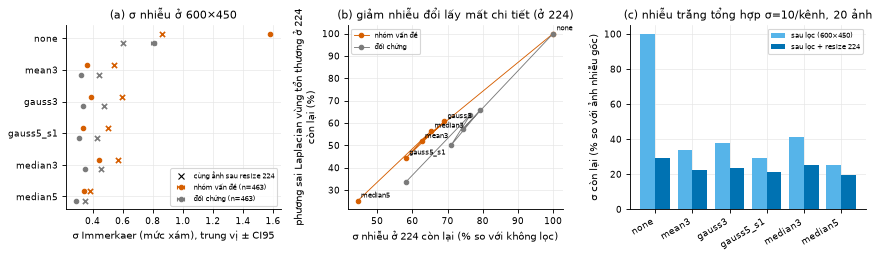

,group,method,n,sigma_med,sigma_imm,sigma_imm_224,sigma_imm_224_ratio,lapvar_224_ratio,lapvar_les_224_ratio,dab,contrast,tenengrad_224_ratio,t_ms
0,problem,none,463,2.430,1.580,0.861,1.000,1.000,1.000,0.000,59.242,1.000,0.002
1,problem,mean3,463,0.706,0.360,0.542,0.626,0.510,0.518,1.653,59.191,0.852,2.419
2,problem,gauss3,463,0.832,0.390,0.597,0.690,0.599,0.607,1.344,59.196,0.885,1.358
3,problem,gauss5_s1,463,0.608,0.338,0.504,0.582,0.439,0.444,1.589,59.319,0.812,1.897
4,problem,median3,463,0.713,0.442,0.567,0.653,0.552,0.564,1.690,59.249,0.856,0.886
5,problem,median5,463,0.461,0.342,0.385,0.444,0.245,0.251,2.106,59.798,0.667,5.620
6,control,none,463,1.303,0.808,0.599,1.000,1.000,1.000,0.000,63.762,1.000,0.002
7,control,mean3,463,0.532,0.323,0.446,0.744,0.578,0.574,1.120,63.679,0.885,2.301
8,control,gauss3,463,0.594,0.337,0.477,0.792,0.657,0.656,0.903,63.686,0.911,1.353
9,control,gauss5_s1,463,0.480,0.309,0.427,0.710,0.509,0.501,1.063,63.670,0.853,1.793


In [4]:
if RECOMPUTE or not (OUT / "image_metrics_noise.csv").exists():
    IM.run("noise", N_JOBS)
dn = pd.read_csv(OUT / "image_metrics_noise.csv")
print(dn.groupby("group").image_id.nunique().to_dict(), "| phương pháp:", dn.method.unique().tolist())
fig, Sn = F.fig_noise_metrics(dn, wn); plt.show()
cols = ["sigma_med", "sigma_imm", "sigma_imm_224", "sigma_imm_224_ratio", "lapvar_224_ratio", "lapvar_les_224_ratio",
        "dab", "contrast"]
Sn2 = F.summarize(dn, ["sigma_med", "sigma_imm", "sigma_imm_224", "lapvar_224", "lapvar_les_224", "tenengrad_224",
                       "hf_224", "dab", "contrast", "entropy", "t_ms"])
Sn2.to_csv(OUT / "summary_noise.csv", index=False)
Sn2[["group", "method", "n"] + cols + ["tenengrad_224_ratio", "t_ms"]].round(3)

**Hình P1.** (a) σ nhiễu (Immerkaer, vùng phẳng) theo phương pháp; chấm tròn = 600×450 (± CI95 bootstrap của trung vị),
dấu × = cùng ảnh sau resize 224. (b) Đánh đổi ở độ phân giải CNN: trục x = σ ở 224 còn lại, trục y = phương sai Laplacian
trong vùng tổn thương ở 224 còn lại (trung vị tỉ lệ theo từng ảnh, so với không lọc). (c) Nhiễu trắng tổng hợp
(ảnh phẳng 128 + N(0, 10²) mỗi kênh, 20 ảnh): σ còn lại sau lọc, và sau lọc + resize. n = 463 ảnh nhóm nhiễu, 463 đối chứng (train_fit).

Ô tiếp theo tính các con số dùng trong phần nhận xét (trích trực tiếp từ `summary_noise.csv`).

In [5]:
S = Sn2.set_index(["group", "method"])
p, c = S.loc["problem"], S.loc["control"]
print(f"Nhóm nhiễu, không lọc: σ_imm 600×450 = {p.loc['none','sigma_imm']:.2f}, ở 224 = {p.loc['none','sigma_imm_224']:.2f}"
      f" (tỉ lệ theo ảnh {p.loc['none','sigma_imm_224']/p.loc['none','sigma_imm']:.2f}); đối chứng: {c.loc['none','sigma_imm']:.2f} → {c.loc['none','sigma_imm_224']:.2f}")
print(f"Chênh nhóm nhiễu − đối chứng: 600×450 {p.loc['none','sigma_imm']-c.loc['none','sigma_imm']:.2f}, 224 {p.loc['none','sigma_imm_224']-c.loc['none','sigma_imm_224']:.2f} mức xám")
print(f"Nhiễu trắng: resize một mình giữ {wn.set_index('method').loc['none','ratio_224']:.2f} σ")
for m in ["mean3", "gauss3", "gauss5_s1", "median3", "median5"]:
    print(f"{m:10s} nhóm nhiễu: σ224 còn {100*p.loc[m,'sigma_imm_224_ratio']:.0f}% (Δ = {p.loc['none','sigma_imm_224']-p.loc[m,'sigma_imm_224']:.2f} mức xám), "
          f"Laplacian tổn thương còn {100*p.loc[m,'lapvar_les_224_ratio']:.0f}%, Tenengrad còn {100*p.loc[m,'tenengrad_224_ratio']:.0f}%, Δab {p.loc[m,'dab']:.2f}")
# Thiên lệch của bộ đo EDA sau lọc trung vị: so sánh tỉ lệ giảm theo 2 bộ đo
print("\nTỉ lệ σ còn lại ở 600×450 theo bộ đo EDA (trung vị) vs Immerkaer, nhóm nhiễu:")
print((p[["sigma_med_ratio", "sigma_imm_ratio"]]).round(2).T)

Nhóm nhiễu, không lọc: σ_imm 600×450 = 1.58, ở 224 = 0.86 (tỉ lệ theo ảnh 0.54); đối chứng: 0.81 → 0.60
Chênh nhóm nhiễu − đối chứng: 600×450 0.77, 224 0.26 mức xám
Nhiễu trắng: resize một mình giữ 0.29 σ
mean3      nhóm nhiễu: σ224 còn 63% (Δ = 0.32 mức xám), Laplacian tổn thương còn 52%, Tenengrad còn 85%, Δab 1.65
gauss3     nhóm nhiễu: σ224 còn 69% (Δ = 0.26 mức xám), Laplacian tổn thương còn 61%, Tenengrad còn 89%, Δab 1.34
gauss5_s1  nhóm nhiễu: σ224 còn 58% (Δ = 0.36 mức xám), Laplacian tổn thương còn 44%, Tenengrad còn 81%, Δab 1.59
median3    nhóm nhiễu: σ224 còn 65% (Δ = 0.29 mức xám), Laplacian tổn thương còn 56%, Tenengrad còn 86%, Δab 1.69
median5    nhóm nhiễu: σ224 còn 44% (Δ = 0.48 mức xám), Laplacian tổn thương còn 25%, Tenengrad còn 67%, Δab 2.11

Tỉ lệ σ còn lại ở 600×450 theo bộ đo EDA (trung vị) vs Immerkaer, nhóm nhiễu:
method           none  mean3  gauss3  gauss5_s1  median3  median5
sigma_med_ratio   1.0   0.29    0.34       0.25     0.29     0.19
sigma_imm_rati

,image_id,dx,rule,sigma_imm,noise_sigma
0,ISIC_0027165,nv,trung vị,1.580107,2.379992
1,ISIC_0032355,nv,cực trị,2.989752,3.718292


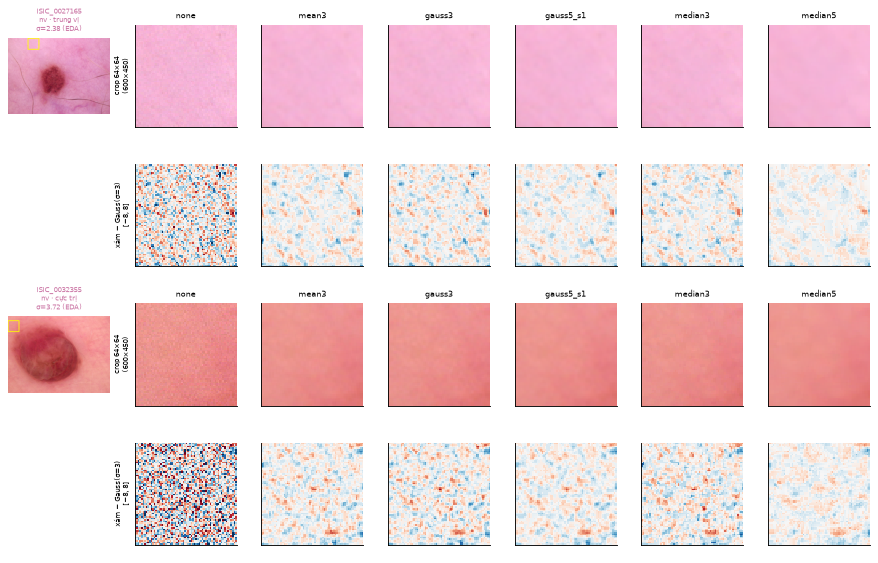

In [6]:
ex_n = F.pick_examples(dn, "sigma_imm").merge(q[["image_id", "noise_sigma"]], on="image_id")
ex_n = ex_n.assign(sigma_med=ex_n["noise_sigma"])
display(ex_n[["image_id", "dx", "rule", "sigma_imm", "noise_sigma"]])
F.grid_noise(ex_n, paths); plt.show()

**Hình P2.** Trước/sau khử nhiễu ở độ phân giải gốc. Quy tắc chọn ảnh: trong nhóm nhiễu ∩ train_fit, ảnh có σ (Immerkaer)
gần trung vị nhất và ảnh có σ lớn nhất. Crop 64×64 đặt tại nơi mật độ pixel vùng phẳng cao nhất (khung vàng ở cột đầu).
Hàng dưới mỗi ảnh: phần dư xám − Gauss(σ = 3) cùng thang [−8, 8] mức xám, để thấy "hạt" nhiễu và vân bị xóa.

### A.5 Nhận xét định lượng (nhiễu)

*(Số trích từ ô in ở trên / `outputs/preprocess/summary_noise.csv`.)*

**Quan sát** (Hình P1, bảng `summary_noise.csv`; n = 463 + 463 ảnh train_fit):

1. **Resize đã là bộ lọc mạnh với nhiễu trắng**: σ còn 29% chỉ nhờ resize (Hình P1c). Với ảnh thật, σ (Immerkaer) của nhóm nhiễu
   giảm từ 1.58 → 0.86 mức xám (tỉ lệ theo ảnh 0.55), nhóm đối chứng 0.81 → 0.60 (0.78). Ảnh thật giảm ít hơn nhiễu trắng → nhiễu
   thật tương quan không gian và/hoặc bộ đo ở 224 lẫn kết cấu da (diễn giải, chưa tách được hai nguyên nhân).
2. **Ở độ phân giải CNN, nhóm "nhiễu" gần như không còn khác đối chứng**: chênh σ giữa hai nhóm giảm từ 0.77 (600×450) xuống 0.26 mức xám (224),
   tức ≈ 0.0045 đơn vị sau Normalize ImageNet.
3. **Lọc giảm thêm rất ít nhiễu nhưng xóa nhiều chi tiết**: ở 224, trong nhóm nhiễu, các bộ lọc giảm σ thêm 0.26–0.48 mức xám
   (còn 44–69%), trong khi phương sai Laplacian vùng tổn thương chỉ còn 25–61%, Tenengrad còn 67–89%. Đường đánh đổi (Hình P1b) gần như một
   đường thẳng: không bộ lọc nào giảm nhiễu "miễn phí". `gauss3` (nhân slide 53) giữ chi tiết nhiều nhất (61%); `median3` không giữ chi tiết
   tốt hơn `gauss3` (56% vs 61%) – nhận xét "trung vị không làm mờ" của slide đúng với **cạnh bậc thang**, còn vân mảnh
   (mạng lưới sắc tố) vẫn bị xóa (Hình P2, hàng phần dư). `mean3` bị `gauss3` lấn át (giảm nhiễu tương đương, mất chi tiết nhiều hơn);
   `median5`/`gauss5_s1` xóa 56–75% năng lượng Laplacian tổn thương.
4. Hai bộ đo nhiễu cho xếp hạng tương tự; thiên lệch của bộ đo EDA sau lọc trung vị nhỏ hơn lo ngại (median3: tỉ lệ còn lại 0.29 theo bộ đo EDA vs 0.28 theo Immerkaer).
5. Bộ lọc không đổi `contrast` (59.2 → 59.2–59.8). Δab theo pixel 1.3–2.1 phản ánh việc xóa nhiễu màu từng pixel, không phải dịch màu vùng.

**Diễn giải (thận trọng):** sau resize, phần nhiễu mà lọc còn loại được chỉ ~0.3 mức xám, nhỏ hơn nhiều so với tương phản da–tổn thương
(trung vị ~60). Cái giá là mất 40–75% năng lượng chi tiết mịn ở 224. Vì vậy **giả thuyết H-N giữ nguyên**: kỳ vọng khử nhiễu không cải thiện
rõ macro-F1, có thể giảm nhẹ với bộ lọc 5×5. Lưu ý nhóm nhiễu gồm 88% `nv` (407/463 ở train_fit) và chủ yếu `follow_up`: nếu CNN dùng
"kết cấu thiết bị" làm shortcut, khử nhiễu có thể đổi precision/recall của `nv` – chỉ kiểm chứng được ở giai đoạn 2.

## B. Tương phản tổn thương–da thấp

### B.1 Vấn đề và bằng chứng từ EDA (mục 2.3)

- Chỉ số `contrast` = mức xám TB vùng da − mức xám TB vùng tổn thương; mask tổn thương ước lượng thô bằng Otsu (Ch.5)
  + đóng/mở (Ch.7), vùng da = FOV trừ tổn thương nở 31 px và lông.
- Ngưỡng tuyệt đối < 20 mức xám (≈ 8% dải) → **435 ảnh** (4.3%); độ nhạy theo ngưỡng đã báo cáo ở EDA.
- Nhóm này có histogram hẹp, 1 đỉnh: P5–P95 = 38 so với 84; std 12.3 so với 26.4. Liên quan loại tổn thương
  (ε² theo `dx` = 0.115; bcc 14.1%, akiec 12.7% so với mel 1.6%, nv 2.2%), gần như không liên quan nguồn ảnh (ε² theo `dx_type` = 0.008).

In [7]:
print(rules.loc["low_contrast", ["metric", "threshold", "rule"]].to_dict())
display(pd.crosstab(qf.F_low_contrast, qf.dx, margins=True))
display(qf.groupby("F_low_contrast")[["contrast", "gray_std", "entropy", "noise_sigma"]].median().round(2))

{'metric': 'contrast', 'threshold': 20.0, 'rule': 'mức xám da − mức xám tổn thương < 20 (≈ 8% dải 0–255)'}


dx,akiec,bcc,bkl,df,mel,nv,vasc,All
F_low_contrast,,,,,,,,
False,285,435,985,104,1098,6537,136,9580
True,42,79,114,11,15,168,6,435
All,327,514,1099,115,1113,6705,142,10015


,contrast,gray_std,entropy,noise_sigma
F_low_contrast,,,,
False,62.10,26.4,6.19,1.34
True,16.49,12.3,5.54,1.20


### B.2 Lập luận và giả thuyết (viết TRƯỚC khi đo)

1. **Toàn cục vs cục bộ.** Giãn tuyến tính và cân bằng histogram là toán tử **điểm** (một LUT cho cả ảnh): vì vùng da
   và tổn thương chiếm hai dải mức xám khác nhau (dù gần nhau), LUT có độ dốc > 1 trên dải đó sẽ **tăng trực tiếp**
   chênh da − tổn thương. CLAHE cân bằng **từng ô** (75×56 px) rồi nội suy: trong mỗi ô nó kéo giãn dải cục bộ, nên tăng
   kết cấu/cạnh nhỏ, nhưng tổn thương lớn hơn một ô sẽ bị "chuẩn hóa" về cùng mặt bằng với da → kỳ vọng CLAHE tăng chỉ
   số `contrast` (đo trên vùng lớn) **ít hơn nhiều** so với phương pháp toàn cục, dù ảnh trông "rõ" hơn.
2. **Giãn tuyến tính không thêm thông tin:** nó nhân cả tín hiệu lẫn nhiễu với cùng hệ số, tỉ số tương phản/nhiễu
   không đổi; ảnh 8-bit còn bị "răng lược" histogram (chỉ ~38 mức được dùng, giãn ra 255). Tác dụng thực đối với CNN
   (nếu có) là **chuẩn hóa dải động theo từng ảnh** – thứ mà `Normalize` cố định theo ImageNet không làm được.
3. **Rủi ro:** (i) khuếch đại nhiễu và lông (nét tối mảnh) – đo σ ở 224 và tỉ lệ pixel lông sau xử lý; (ii) đổi màu –
   xử lý trên L\* (Lab) hoặc V (HSV), đo Δab (chỉ phần màu); (iii) **lệch phân phối** khỏi ảnh ImageNet mà
   ResNet-18 pretrained đã quen – áp dụng cho *mọi* ảnh (cả 95.7% ảnh không có vấn đề), nên phương pháp làm thay đổi mạnh
   ảnh bình thường (cân bằng histogram) có rủi ro cao nhất; (iv) mask Otsu là ước lượng thô.
4. **Màu là tín hiệu chẩn đoán** (ví dụ vùng xanh xám, đỏ của mạch máu) → không cân bằng từng kênh RGB.

**Giả thuyết H-C (cho CNN):** phương pháp toàn cục tăng mạnh chỉ số `contrast` nhưng cũng thay đổi mạnh ảnh bình thường;
CLAHE thay đổi vừa phải. Kỳ vọng **không có phương pháp nào cải thiện rõ macro-F1 toàn tập**, vì nhóm tương phản thấp chỉ
chiếm ~4% và CNN có BatchNorm/fine-tune có thể tự bù độ lợi tuyến tính; nếu có lợi, kỳ vọng thấy ở F1 của `bcc`, `akiec`, `bkl`
(các lớp có tỉ lệ tương phản thấp cao nhất) và ở tỉ lệ lỗi trong nhóm tương phản thấp. Cân bằng histogram toàn cục có nguy cơ
**giảm** F1 (đổi mạnh ảnh bình thường, khuếch đại nhiễu).

### B.3 Phương pháp, tham số và lý do

| Tên | Phương pháp | Tham số | Lý do |
|---|---|---|---|
| `stretch_L_1_99` | Giãn tương phản tuyến tính từng đoạn (Ch.3 slide 21) trên L\* | [P1, P99] của L\* trong FOV → [0, 255] | Phân vị thay min/max để vài pixel lông/phản quang không quyết định hệ số giãn |
| `hist_eq_L` | Cân bằng lược đồ xám (slide 32–36) trên L\* | CDF tính trong FOV | Phương pháp toàn cục chuẩn của Ch.3, không tham số |
| `clahe_L_c{1,2,3}_t8` | CLAHE trên L\* | clip ∈ {1, 2, 3}, lưới 8×8 | Lưới 8×8 → ô 75×56 px (cỡ một phần tổn thương); clip 2 là mặc định thường dùng, 1 và 3 để xem liều–đáp ứng |
| `clahe_V_c2_t8` | CLAHE trên V (HSV, Ch.4) | clip 2, 8×8 | Đối chứng hệ màu: V của slide Ch.4 vs L\* |

FOV (bỏ viền đen ống soi) dùng cùng bộ đo với EDA; thống kê (phân vị, CDF) chỉ tính trong FOV để viền đen không chiếm dải mức xám.
Không thử gamma/log: chúng xử lý độ sáng toàn ảnh (quá sáng/tối), không nhắm vào chênh da − tổn thương; ngoài phạm vi 2 vấn đề này.

### B.4 Đánh giá ảnh trước/sau

Nhóm tương phản thấp ∩ `train_fit` (n = 275) + đối chứng cùng cỡ (seed 42). Mask tham chiếu từ ảnh gốc.

{'control': 275, 'problem': 275}


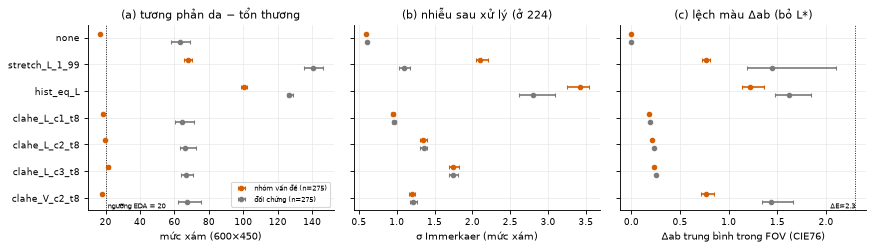

,group,method,n,contrast,contrast_ratio,p5_p95,entropy,sigma_imm_224,sigma_imm_224_ratio,lapvar_les_224_ratio,dE76,dab,hair_frac,t_ms
0,problem,none,275,16.542,1.000,39.0,5.577,0.597,1.000,1.000,0.000,0.000,0.004,0.002
1,problem,stretch_L_1_99,275,67.645,4.200,172.0,6.472,2.105,3.542,12.551,13.029,0.768,0.364,67.744
2,problem,hist_eq_L,275,100.378,6.138,225.0,6.321,3.422,5.508,12.744,23.569,1.223,0.537,73.497
3,problem,clahe_L_c1_t8,275,18.222,1.112,50.0,5.947,0.949,1.597,2.676,1.706,0.179,0.031,63.274
4,problem,clahe_L_c2_t8,275,19.872,1.225,65.0,6.312,1.351,2.268,5.206,3.310,0.215,0.127,61.393
5,problem,clahe_L_c3_t8,275,21.592,1.337,81.0,6.605,1.748,2.936,8.313,4.904,0.232,0.266,57.238
6,problem,clahe_V_c2_t8,275,18.029,1.106,53.0,5.996,1.203,2.005,3.266,2.799,0.771,0.057,69.871
7,control,none,275,63.355,1.000,83.0,6.214,0.600,1.000,1.000,0.000,0.000,0.008,0.002
8,control,stretch_L_1_99,275,140.498,2.074,195.0,6.916,1.090,1.710,3.472,14.356,1.444,0.090,61.361
9,control,hist_eq_L,275,126.786,1.982,224.0,6.701,2.804,4.395,0.618,21.605,1.620,0.400,64.665


In [8]:
if RECOMPUTE or not (OUT / "image_metrics_contrast.csv").exists():
    IM.run("contrast", N_JOBS)
dc = pd.read_csv(OUT / "image_metrics_contrast.csv")
print(dc.groupby("group").image_id.nunique().to_dict())
fig, _ = F.fig_contrast_metrics(dc); plt.show()
Sc = F.summarize(dc, ["contrast", "p5_p95", "entropy", "sigma_imm_224", "lapvar_les_224", "dE76", "dab", "hair_frac", "t_ms"])
Sc.to_csv(OUT / "summary_contrast.csv", index=False)
Sc[["group", "method", "n", "contrast", "contrast_ratio", "p5_p95", "entropy", "sigma_imm_224", "sigma_imm_224_ratio",
    "lapvar_les_224_ratio", "dE76", "dab", "hair_frac", "t_ms"]].round(3)

**Hình P3.** Tác động của các phương pháp tăng tương phản, trung vị ± CI95 bootstrap, n = 275 ảnh tương phản thấp và 275 đối chứng (train_fit).
(a) Chỉ số `contrast` (da − tổn thương, mask cố định của ảnh gốc), đường chấm = ngưỡng EDA 20. (b) σ nhiễu Immerkaer ở 224 sau xử lý
(khuếch đại nhiễu). (c) Δab = lệch màu chỉ tính a\*, b\* (bỏ L\*), đường chấm ≈ ngưỡng phân biệt màu ΔE ≈ 2.3 (quy ước thường dùng – cần kiểm chứng nguồn).

In [9]:
S = Sc.set_index(["group", "method"]); p, c = S.loc["problem"], S.loc["control"]
for m in CONTRAST_CANDIDATES:
    print(f"{m:15s} contrast: thấp {p.loc[m,'contrast']:6.1f} | đối chứng {c.loc[m,'contrast']:6.1f}  ||  "
          f"σ224 ×{p.loc[m,'sigma_imm_224_ratio']:.2f} | Δab {p.loc[m,'dab']:.2f}/{c.loc[m,'dab']:.2f} | "
          f"ΔE76 đối chứng {c.loc[m,'dE76']:.1f} | lông {p.loc[m,'hair_frac']:.3f}")
# Tỉ số tương phản / nhiễu (600×450, Immerkaer) – giãn tuyến tính có giữ nguyên không?
dd = dc.assign(cnr=dc.contrast / dc.sigma_imm)
display(dd.groupby(["group", "method"], sort=False).cnr.median().unstack(0).round(1))
# Tỉ lệ ảnh còn dưới ngưỡng EDA (contrast < 20) sau xử lý, trong nhóm tương phản thấp
display(dc[dc.group == "problem"].groupby("method", sort=False).contrast.apply(lambda x: (x < 20).mean()).round(3).rename("tỉ lệ còn < 20"))
# Phân phối kênh ở 224 so với ImageNet (pooled trên ảnh đối chứng ≈ ảnh bình thường)
def pooled(d):
    out = {}
    for ch in "RGB":
        out[f"mean_{ch}"] = d[f"mean_{ch}"].mean()
        out[f"std_{ch}"] = np.sqrt((d[f"std_{ch}"] ** 2).mean() + d[f"mean_{ch}"].var())
    return pd.Series(out)
dist = dc[dc.group == "control"].groupby("method", sort=False)[[f"{k}_{ch}" for ch in "RGB" for k in ("mean", "std")]].apply(pooled)
dist.loc["ImageNet"] = [0.485, 0.229, 0.456, 0.224, 0.406, 0.225]
dist.to_csv(OUT / "channel_stats_vs_imagenet.csv"); dist.round(3)

none            contrast: thấp   16.5 | đối chứng   63.4  ||  σ224 ×1.00 | Δab 0.00/0.00 | ΔE76 đối chứng 0.0 | lông 0.004
stretch_L_1_99  contrast: thấp   67.6 | đối chứng  140.5  ||  σ224 ×3.54 | Δab 0.77/1.44 | ΔE76 đối chứng 14.4 | lông 0.364
hist_eq_L       contrast: thấp  100.4 | đối chứng  126.8  ||  σ224 ×5.51 | Δab 1.22/1.62 | ΔE76 đối chứng 21.6 | lông 0.537
clahe_L_c1_t8   contrast: thấp   18.2 | đối chứng   64.4  ||  σ224 ×1.60 | Δab 0.18/0.20 | ΔE76 đối chứng 1.9 | lông 0.031
clahe_L_c2_t8   contrast: thấp   19.9 | đối chứng   66.1  ||  σ224 ×2.27 | Δab 0.21/0.23 | ΔE76 đối chứng 3.6 | lông 0.127
clahe_L_c3_t8   contrast: thấp   21.6 | đối chứng   66.7  ||  σ224 ×2.94 | Δab 0.23/0.26 | ΔE76 đối chứng 5.2 | lông 0.266
clahe_V_c2_t8   contrast: thấp   18.0 | đối chứng   67.5  ||  σ224 ×2.00 | Δab 0.77/1.44 | ΔE76 đối chứng 4.1 | lông 0.057


group,problem,control
method,,
none,21.3,75.7
stretch_L_1_99,19.6,71.9
hist_eq_L,18.5,26.8
clahe_L_c1_t8,11.8,39.5
clahe_L_c2_t8,8.9,27.7
clahe_L_c3_t8,7.4,21.4
clahe_V_c2_t8,8.6,30.1


method
none              1.000
stretch_L_1_99    0.004
hist_eq_L         0.004
clahe_L_c1_t8     0.687
clahe_L_c2_t8     0.509
clahe_L_c3_t8     0.382
clahe_V_c2_t8     0.695
Name: tỉ lệ còn < 20, dtype: float64

,mean_R,std_R,mean_G,std_G,mean_B,std_B
method,,,,,,
none,0.764,0.145,0.552,0.162,0.574,0.179
stretch_L_1_99,0.825,0.224,0.640,0.264,0.664,0.277
hist_eq_L,0.619,0.271,0.436,0.290,0.463,0.300
clahe_L_c1_t8,0.766,0.142,0.554,0.162,0.577,0.179
clahe_L_c2_t8,0.758,0.145,0.546,0.165,0.570,0.182
clahe_L_c3_t8,0.749,0.151,0.538,0.169,0.562,0.185
clahe_V_c2_t8,0.728,0.146,0.529,0.163,0.551,0.180
ImageNet,0.485,0.229,0.456,0.224,0.406,0.225


,image_id,dx,rule,contrast
105,ISIC_0028308,bkl,trung vị,16.542307
56,ISIC_0026104,bkl,cực trị,-2.148804


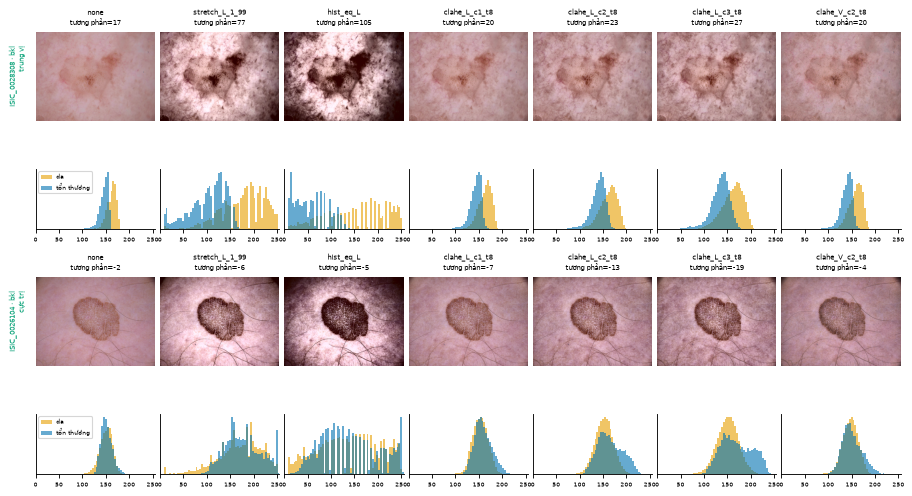

In [10]:
ex_c = F.pick_examples(dc, "contrast")
display(ex_c[["image_id", "dx", "rule", "contrast"]])
F.grid_contrast(ex_c, paths, ["none", "stretch_L_1_99", "hist_eq_L", "clahe_L_c1_t8", "clahe_L_c2_t8", "clahe_L_c3_t8", "clahe_V_c2_t8"]); plt.show()

**Hình P4.** Trước/sau tăng tương phản. Quy tắc chọn: trong nhóm tương phản thấp ∩ train_fit, ảnh có `contrast` gần trung vị nhất và ảnh
có `contrast` nhỏ nhất. Dưới mỗi ảnh: histogram mức xám của vùng da (cam) và tổn thương (xanh) theo mask cố định của ảnh gốc; tiêu đề ghi `contrast` sau xử lý.

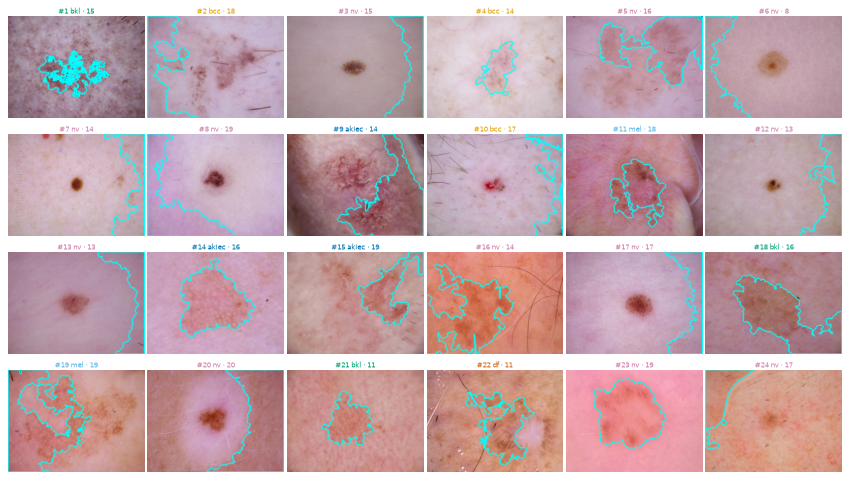

mask_audit
sai         10
đúng         9
một phần     5
Name: count, dtype: int64

mask_audit,một phần,sai,đúng
dx,,,
akiec,2,0,1
bcc,1,1,1
bkl,0,0,3
df,0,0,1
mel,1,0,1
nv,1,9,2


In [11]:
# Kiểm tra mask tổn thương bằng mắt: 24 ảnh ngẫu nhiên (seed 42) của nhóm tương phản thấp ∩ train_fit
fig, aud = F.grid_mask_audit(dc, paths); plt.show()
audit = pd.read_csv(OUT / "lowcontrast_mask_audit.csv")   # nhãn bằng mắt (AI), cần người kiểm tra lại
assert list(audit.image_id) == list(aud.image_id)
display(audit.mask_audit.value_counts()); display(pd.crosstab(audit.dx, audit.mask_audit))

**Hình P5.** Mask tổn thương (viền xanh, Otsu + hình thái học của EDA) trên 24 ảnh rút ngẫu nhiên (seed 42) từ nhóm tương phản thấp ∩ train_fit;
tiêu đề: số thứ tự, lớp, `contrast`. Nhãn đúng / một phần / sai trong `lowcontrast_mask_audit.csv` do AI đánh giá bằng mắt, cần người kiểm tra lại.

### B.5 Nhận xét định lượng (tương phản)

**Quan sát** (Hình P3, P4, bảng `summary_contrast.csv`; n = 275 + 275 ảnh train_fit):

1. **Phương pháp toàn cục tăng `contrast` mạnh, CLAHE gần như không**: nhóm tương phản thấp 16.5 → 67.6 (`stretch_L_1_99`), 100.4 (`hist_eq_L`),
   nhưng chỉ 18.2 / 19.9 / 21.6 với CLAHE clip 1/2/3; sau CLAHE c2 vẫn còn 51% ảnh dưới ngưỡng 20 (stretch, hist_eq: 0.4%). Đúng như lập luận
   B.2(1): CLAHE tăng kết cấu cục bộ (P5–P95 39 → 65, entropy 5.58 → 6.31) chứ không tăng chênh lệch giữa hai vùng lớn.
2. **Nhưng phương pháp toàn cục cũng biến đổi mạnh ảnh bình thường**: ở nhóm đối chứng, `contrast` 63 → 140 (stretch) / 127 (hist_eq), ΔE76 trung bình
   14.4 / 21.6, so với 1.9–5.2 của CLAHE-L. Phép xử lý áp dụng cho mọi ảnh, nên đây là thay đổi phân phối đầu vào trên toàn tập.
3. **Khuếch đại nhiễu**: σ ở 224 tăng ×3.5 (stretch), ×5.5 (hist_eq), ×1.6/×2.3/×2.9 (CLAHE c1/c2/c3) trong nhóm tương phản thấp. Tỉ số tương phản/nhiễu
   (600×450) gần như giữ nguyên với stretch (21.3 → 19.6, giảm nhẹ do bão hòa ở hai đầu) – khớp lập luận "giãn tuyến tính không thêm thông tin" –
   nhưng giảm với CLAHE (→ 8.9 với c2) và với hist_eq ở đối chứng (75.7 → 26.8). Tỉ lệ pixel "lông" (black-hat ≥ 20, ngưỡng tuyệt đối) tăng mạnh
   (0.004 → 0.36 với stretch): một phần do ngưỡng tuyệt đối gặp ảnh đã giãn, nhưng cũng cho thấy nét tối mảnh bị làm nổi.
4. **Giữ màu**: xử lý trên L\* giữ màu tốt (Δab 0.18–0.26 với CLAHE-L); cùng CLAHE c2 nhưng trên V (HSV) cho Δab 0.77 (nhóm thấp) / 1.44 (đối chứng),
   gấp 3–6 lần → chọn L\* cho mọi phương pháp tăng tương phản.
5. **Thống kê kênh ở 224 (ảnh đối chứng)**: stretch đưa std kênh gần ImageNet hơn (0.145–0.179 → 0.224–0.277; ImageNet ~0.225) nhưng mean xa hơn
   (R 0.76 → 0.83; ImageNet 0.485); hist_eq ngược lại (mean gần hơn, std lớn hơn). Không phương pháp nào "khớp ImageNet"; tác động lên fine-tune chỉ đo được bằng CNN.
6. **Hình P4**: stretch và hist_eq làm bão hòa vùng tối của tổn thương và làm tối góc ảnh; histogram sau giãn có dạng "răng lược" (ảnh 8-bit chỉ có ~40 mức gốc).

**Cảnh báo về chỉ số `contrast` (phát hiện ở giai đoạn này):** ảnh cực trị trong Hình P4 (`ISIC_0026104`, contrast = −2) có tổn thương sẫm, nhìn rõ –
mask Otsu đã chọn sai vùng. Kiểm tra bằng mắt 24 ảnh ngẫu nhiên (seed 42) của nhóm tương phản thấp ∩ train_fit (Hình P5,
`outputs/preprocess/lowcontrast_mask_audit.csv`): mask **sai** ở 10/24, **một phần** ở 5/24, **đúng** ở 9/24 (AI đánh giá bằng mắt – **cần người kiểm tra lại**).
Lỗi điển hình: tổn thương nhỏ, tương phản tốt (chủ yếu `nv`, 8/10 ca sai) nhưng mask lấy vùng rìa tối do chiếu sáng không đều. Hệ quả:
(i) con số 435 ảnh của EDA có thể bị **đếm thừa** đáng kể; (ii) số đo `contrast` trước/sau ở trên chỉ tin được cho phần ảnh có mask đúng;
(iii) ở giai đoạn 2, phân tích "nhóm tương phản thấp" phải kèm hạn chế này hoặc dùng tập con đã kiểm tra mask. Đề nghị nhóm xem lại mục 2.3 của EDA.

**Diễn giải:** giả thuyết H-C được củng cố một phần ở mức ảnh: (a) chỉ phương pháp toàn cục thực sự kéo chênh lệch da–tổn thương lên, nhưng với cái giá biến đổi
mạnh toàn bộ tập; (b) CLAHE thay đổi phân phối "nhẹ" nhưng không giải quyết đúng vấn đề đo được và khuếch đại nhiễu. Kỳ vọng không phương pháp nào cải thiện rõ
macro-F1 toàn tập; `hist_eq_L` là ứng viên có rủi ro giảm F1 cao nhất.

## C. Kết hợp khử nhiễu → tăng tương phản (thứ tự)

Lập luận thứ tự: tăng tương phản nhân/khuếch đại nhiễu, nên khử nhiễu phải đứng **trước**. Đo trên nhóm tương phản thấp: khử nhiễu trước có
kéo σ sau tăng tương phản về gần mức gốc không, và có làm mất phần tương phản đạt được không.

In [12]:
if RECOMPUTE or not (OUT / "image_metrics_combo.csv").exists():
    IM.run("combo", N_JOBS)
dk = pd.read_csv(OUT / "image_metrics_combo.csv")
Sk = F.summarize(dk, ["contrast", "sigma_imm_224", "lapvar_les_224", "dab", "t_ms"])
Sk.to_csv(OUT / "summary_combo.csv", index=False)
Sk[["group", "method", "n", "contrast", "sigma_imm_224", "sigma_imm_224_ratio", "lapvar_les_224_ratio", "dab", "t_ms"]].round(3)

,group,method,n,contrast,sigma_imm_224,sigma_imm_224_ratio,lapvar_les_224_ratio,dab,t_ms
0,problem,none,275,16.542,0.597,1.000,1.000,0.000,0.003
1,problem,stretch_L_1_99,275,67.645,2.105,3.542,12.551,0.768,77.258
2,problem,gauss3+stretch_L_1_99,275,69.437,1.454,2.471,8.632,1.248,81.847
3,problem,median3+stretch_L_1_99,275,69.715,1.365,2.268,8.165,1.394,80.971
4,problem,clahe_L_c2_t8,275,19.872,1.351,2.268,5.206,0.215,69.827
5,problem,gauss3+clahe_L_c2_t8,275,20.265,0.927,1.560,3.413,0.786,71.607
6,problem,median3+clahe_L_c2_t8,275,20.251,0.875,1.462,3.160,0.929,69.102
7,control,none,275,63.355,0.600,1.000,1.000,0.000,0.003
8,control,stretch_L_1_99,275,140.498,1.090,1.710,3.472,1.444,75.444
9,control,gauss3+stretch_L_1_99,275,141.437,0.762,1.205,2.317,2.077,76.117


**Quan sát** (bảng trên, `summary_combo.csv`, nhóm tương phản thấp n = 275): khử nhiễu trước khi tăng tương phản giảm hệ số khuếch đại nhiễu ở 224 từ
×2.27 → ×1.46 (`median3` + CLAHE c2) / ×1.56 (`gauss3` + CLAHE c2), và từ ×3.54 → ×2.27 / ×2.47 với stretch, mà `contrast` không giảm (19.9 → 20.3; 67.6 → 69.7).
Đổi lại Δab tăng lên 0.8–1.4 (phần xóa nhiễu màu của bộ lọc). → Nếu kết hợp, thứ tự **khử nhiễu → tăng tương phản** hợp lý về mặt ảnh;
lợi ích cho CNN cần kiểm chứng ở giai đoạn 2.

## D. Kiểm tra `preprocess_fn` trên toàn bộ 10 015 ảnh (CPU)

Mỗi ứng viên được chạy trên mọi ảnh (train + test, 600×450): kiểm tra shape/dtype giữ nguyên và đo thời gian/ảnh
(1 luồng OpenCV/tiến trình, 12 tiến trình song song – thời gian có thể cao hơn khi chạy một mình do tranh chấp CPU).

In [13]:
if RECOMPUTE or not (OUT / "preprocess_timing.csv").exists():
    IM.check_all(N_JOBS)
tm = pd.read_csv(OUT / "preprocess_timing.csv")
tm["est_minutes_1_thread"] = tm["est_total_s_single_thread"] / 60
tm.round(2)

,method,n_images,all_ok_shape_dtype,ms_per_image_median,ms_per_image_p95,est_total_s_single_thread,est_minutes_1_thread
0,mean3,10015,True,2.68,5.54,30.73,0.51
1,gauss3,10015,True,2.14,4.88,24.46,0.41
2,gauss5_s1,10015,True,1.58,3.85,19.27,0.32
3,median3,10015,True,0.77,2.27,9.88,0.16
4,median5,10015,True,5.11,10.76,59.91,1.00
5,stretch_L_1_99,10015,True,88.64,125.02,909.65,15.16
6,hist_eq_L,10015,True,89.66,123.00,901.83,15.03
7,clahe_L_c1_t8,10015,True,75.09,103.68,755.35,12.59
8,clahe_L_c2_t8,10015,True,74.50,102.57,747.24,12.45
9,clahe_L_c3_t8,10015,True,74.80,101.36,748.01,12.47


In [14]:
# Kiểm tra nhanh interface cho src.training.run_experiment: callable picklable, uint8 RGB -> cùng shape/dtype
import pickle
rgb = IM.load_rgb(paths[q.image_id.iloc[0]])
for name in ["median3", "gauss3", "stretch_L_1_99", "clahe_L_c2_t8", "median3+clahe_L_c2_t8"]:
    fn = pickle.loads(pickle.dumps(get_preprocess(name)))
    out = fn(rgb)
    before = rgb.copy(); out = fn(rgb)
    assert out.shape == rgb.shape and out.dtype == np.uint8 and np.array_equal(rgb, before)  # không sửa ảnh đầu vào
    print(f"{name:22s} OK {out.shape} {out.dtype}")

median3                OK (450, 600, 3) uint8
gauss3                 OK (450, 600, 3) uint8
stretch_L_1_99         OK (450, 600, 3) uint8
clahe_L_c2_t8          OK (450, 600, 3) uint8
median3+clahe_L_c2_t8  OK (450, 600, 3) uint8


## E. Kế hoạch thí nghiệm CNN (giai đoạn 2)

**Nguyên tắc:** mỗi cấu hình áp dụng cho **toàn bộ ảnh** (train/val/test), chỉ đổi đúng một yếu tố so với baseline (`outputs/baseline/config.json`:
ResNet-18, 224, WRS, AdamW 1e-4, 20 epoch, flip). Sàng lọc chỉ nhìn **val macro-F1** của seed 42; test chỉ đọc sau khi đã chốt cấu hình.

**Bước 1 – sàng lọc (seed 42, 1 lần train mỗi cấu hình):**

| Vấn đề | Cấu hình | Vì sao vào danh sách | Vì sao loại các ứng viên khác |
|---|---|---|---|
| Nhiễu | `gauss3` | Giữ chi tiết tốt nhất ở cùng mức giảm nhiễu (Laplacian tổn thương còn 61%); đúng nhân slide 53 | `mean3`: bị `gauss3` lấn át; `gauss5_s1`, `median5`: mất 56–75% chi tiết |
| Nhiễu | `median3` | Bộ lọc slide khuyên dùng, phi tuyến, giữ cạnh | – |
| Tương phản | `stretch_L_1_99` | Phương pháp toàn cục duy nhất giữ tỉ số tương phản/nhiễu; thực sự kéo `contrast` qua ngưỡng | `hist_eq_L`: biến đổi ảnh bình thường mạnh nhất (ΔE 21.6), khuếch đại nhiễu ×5.5 |
| Tương phản | `clahe_L_c2_t8` | Thay đổi nhẹ ảnh bình thường (ΔE 3.6), giữ màu (Δab 0.23); tham số thông dụng | c1: gần như không đổi; c3: khuếch đại nhiễu ×2.9; V (HSV): lệch màu gấp 3–6 lần |
| *(tùy chọn)* | `hist_eq_L` | Kiểm tra dự đoán "kết quả âm" của phương pháp toàn cục không tham số | – |
| *(tùy chọn)* | `median5` | Liều–đáp ứng: mất chi tiết có làm giảm F1 không | – |

**Quy tắc chọn (đặt trước khi chạy):** mỗi vấn đề chọn cấu hình có val macro-F1 (seed 42) cao nhất. Nếu chênh lệch giữa hai ứng viên nhỏ hơn
std val macro-F1 của baseline qua 3 seed, coi là "không phân biệt được" và chọn cấu hình **ít can thiệp hơn** theo số đo ảnh
(nhiễu: `gauss3` – giữ chi tiết hơn; tương phản: `clahe_L_c2_t8` – ΔE trên ảnh bình thường nhỏ hơn). Báo cáo ghi rõ đây là chọn trên 1 seed,
có thiên lệch "người thắng" khi seed 42 được dùng lại ở bước 2.

**Bước 2 – xác nhận (3 seed: 42, 43, 44):** 1 cấu hình thắng cho mỗi vấn đề → dùng lại seed 42 từ bước 1, chạy thêm 43, 44.

**Bước 3 (tùy chọn) – kết hợp:** `<nhiễu thắng>+<tương phản thắng>` (thứ tự khử nhiễu → tương phản, mục C), 3 seed. Chỉ chạy nếu ít nhất một
thành phần không làm giảm val macro-F1 so với baseline.

**Ước tính số lần train** (1 lần = 1 seed × 20 epoch; baseline = 3 lần):

| Bước | Số lần train |
|---|---|
| Sàng lọc (4 cấu hình chính) | 4 |
| Xác nhận (2 cấu hình × seed 43, 44) | 4 |
| Kết hợp (3 seed) – tùy chọn | 3 |
| **Tổng chính** | **8** (≈ 2.7× baseline); **11** nếu có kết hợp (≈ 3.7×) |
| Tùy chọn `hist_eq_L`, `median5` (1 seed) | +2 → tối đa 13 |

**Chi phí tiền xử lý (CPU, mục D):** bộ lọc nhiễu < 1 phút cho 10 015 ảnh (1 luồng); tăng tương phản trên L\* ~75–90 ms/ảnh → ~12–15 phút/1 luồng
(chủ yếu do chuyển RGB↔Lab float). Nên xử lý 1 lần/cấu hình rồi cache (hoặc song song bằng `multiprocessing` – hàm từ `get_preprocess` picklable), không tính lại cho mỗi seed.

**Phân tích giai đoạn 2:** so với baseline: macro-F1, balanced accuracy, F1 từng lớp (mean ± std 3 seed + điểm từng seed); tỉ lệ lỗi trên nhóm noise / low_contrast
(val và test preds) so với phần còn lại, CI bootstrap. Với nhóm low_contrast, báo cáo kèm cảnh báo mask (B.5).

## F. Thí nghiệm CNN – bước 1: sàng lọc (seed 42, chỉ val)

Huấn luyện bằng `scripts/run_preprocess_experiments.py` (gọi `src.training.run_experiment`, cấu hình đóng băng giống baseline; log ở
`outputs/preprocess/experiments.log`). Notebook này **chỉ đọc kết quả**, không train.

**Lưu ý về quy tắc chọn:** std val macro-F1 của baseline qua 3 seed chỉ là 0.0032, nên quy tắc "chênh < std baseline → chọn cấu hình ít can thiệp"
gần như trở thành "chọn val cao nhất". Trong khi đó dao động giữa seed trên **test** của baseline là 0.019 (gấp ~6 lần), và mô hình được chọn
epoch theo val nên val bị "tối ưu" một phần → chênh lệch val của **1 seed** chỉ là tín hiệu yếu. Sàng lọc chỉ dùng để quyết định cấu hình nào
đáng chạy đủ 3 seed, không phải bằng chứng hiệu quả.

In [15]:
from src.preprocess import compare as CMP
base = CMP.load_summary("baseline")
thr = base.val_macro_f1.std(ddof=1)
print(f"Baseline val macro-F1: seed42 = {base.set_index('seed').loc[42,'val_macro_f1']:.4f}; mean ± std (3 seed) = {base.val_macro_f1.mean():.4f} ± {thr:.4f}")
SCREEN = {"nhiễu": ["gauss3", "median3"], "tương phản": ["stretch_L_1_99", "clahe_L_c2_t8"]}
LESS_INVASIVE = {"nhiễu": "gauss3", "tương phản": "clahe_L_c2_t8"}   # đặt TRƯỚC khi chạy (mục E)
rows, chosen = [], {}
for prob, names in SCREEN.items():
    v = {n: CMP.load_summary(n, (42,)).val_macro_f1.item() for n in names}
    best = max(v, key=v.get); other = [n for n in names if n != best][0]
    tie = abs(v[best] - v[other]) < thr
    chosen[prob] = LESS_INVASIVE[prob] if tie else best
    for n in names:
        rows.append({"vấn đề": prob, "cấu hình": n, "val_macro_f1_seed42": v[n],
                     "Δ so với baseline seed42": v[n] - base.set_index("seed").loc[42, "val_macro_f1"],
                     "chọn": n == chosen[prob], "lý do": ("chênh < std baseline → ít can thiệp" if tie else "val cao nhất") if n == chosen[prob] else ""})
screen_tbl = pd.DataFrame(rows); screen_tbl.to_csv(OUT / "screening_val_seed42.csv", index=False)
display(screen_tbl.round(4)); print("Chọn:", chosen)

Baseline val macro-F1: seed42 = 0.7201; mean ± std (3 seed) = 0.7215 ± 0.0032


,vấn đề,cấu hình,val_macro_f1_seed42,Δ so với baseline seed42,chọn,lý do
0,nhiễu,gauss3,0.7048,-0.0153,False,
1,nhiễu,median3,0.7437,0.0236,True,val cao nhất
2,tương phản,stretch_L_1_99,0.6898,-0.0303,False,
3,tương phản,clahe_L_c2_t8,0.7211,0.0011,True,val cao nhất


Chọn: {'nhiễu': 'median3', 'tương phản': 'clahe_L_c2_t8'}


## G. Bước 2–3: chạy 3 seed và so sánh với baseline

Các cấu hình có đủ 3 seed được đưa vào bảng/hình. Các cột trong `comparison_{val,test}.csv`:
- `*_mean`, `*_std`: mean ± std (ddof = 1) qua 3 seed.
- `*_delta`: Δ so với baseline, ghép cặp theo seed. `*_delta_sign` = số cặp dương/âm.
- `*_delta_ci_lo/hi`: CI95 bootstrap (1000 lần, cụm theo `lesion_id`) của Δ trung bình 3 seed trên ảnh của split.
- `verdict`: "khác biệt rõ" chỉ khi |Δ| > std giữa seed của baseline **và** CI không chứa 0 **và** 3/3 cặp cùng dấu (quy tắc đặt trước).

Huấn luyện dùng AMP + `cudnn.benchmark` nên không tất định từng bit; dao động giữa seed đã bao gồm nguồn này. Test chỉ để báo cáo, không dùng để chọn.

In [16]:
import itertools
CANDS = ["gauss3", "median3", "stretch_L_1_99", "clahe_L_c2_t8", "hist_eq_L", "median5"]
COMBO = f"{chosen['nhiễu']}+{chosen['tương phản']}"
FULL = [n for n in CANDS + [COMBO] if (CMP.run_dir(n) / "summary.csv").exists() and len(CMP.available_seeds(n)) == 3]
ONE_SEED = [n for n in CANDS if (CMP.run_dir(n) / "summary.csv").exists() and len(CMP.available_seeds(n)) < 3]
print("Đủ 3 seed:", FULL, "| chỉ 1 seed (sàng lọc):", ONE_SEED)
cmp_val = CMP.comparison_table(FULL, "val"); cmp_val.to_csv(OUT / "comparison_val.csv", index=False)
cmp_test = CMP.comparison_table(FULL, "test"); cmp_test.to_csv(OUT / "comparison_test.csv", index=False)
show = ["config", "n_seeds", "macro_f1_mean", "macro_f1_std", "macro_f1_delta", "macro_f1_delta_sign", "macro_f1_delta_ci_lo",
        "macro_f1_delta_ci_hi", "macro_f1_verdict", "balanced_acc_mean", "balanced_acc_std", "balanced_acc_delta",
        "balanced_acc_delta_ci_lo", "balanced_acc_delta_ci_hi", "balanced_acc_verdict"]
print("VAL"); display(cmp_val[show].round(4))
print("TEST"); display(cmp_test[show].round(4))

Đủ 3 seed: ['median3', 'clahe_L_c2_t8', 'median3+clahe_L_c2_t8'] | chỉ 1 seed (sàng lọc): ['gauss3', 'stretch_L_1_99', 'hist_eq_L', 'median5']


VAL


,config,n_seeds,macro_f1_mean,macro_f1_std,macro_f1_delta,macro_f1_delta_sign,macro_f1_delta_ci_lo,macro_f1_delta_ci_hi,macro_f1_verdict,balanced_acc_mean,balanced_acc_std,balanced_acc_delta,balanced_acc_delta_ci_lo,balanced_acc_delta_ci_hi,balanced_acc_verdict
0,baseline,3,0.7215,0.0032,NaN,NaN,NaN,NaN,NaN,0.7385,0.0208,NaN,NaN,NaN,NaN
1,median3,3,0.7353,0.0196,0.0138,2+/1-,-0.0102,0.0371,không khác biệt rõ,0.7359,0.0052,-0.0025,-0.0370,0.0246,không khác biệt rõ
2,clahe_L_c2_t8,3,0.7248,0.0041,0.0033,2+/1-,-0.0247,0.0319,không khác biệt rõ,0.7291,0.0279,-0.0093,-0.0387,0.0189,không khác biệt rõ
3,median3+clahe_L_c2_t8,3,0.7236,0.0064,0.0021,2+/1-,-0.0249,0.0298,không khác biệt rõ,0.7239,0.0094,-0.0146,-0.0465,0.0152,không khác biệt rõ


TEST


,config,n_seeds,macro_f1_mean,macro_f1_std,macro_f1_delta,macro_f1_delta_sign,macro_f1_delta_ci_lo,macro_f1_delta_ci_hi,macro_f1_verdict,balanced_acc_mean,balanced_acc_std,balanced_acc_delta,balanced_acc_delta_ci_lo,balanced_acc_delta_ci_hi,balanced_acc_verdict
0,baseline,3,0.6805,0.0192,NaN,NaN,NaN,NaN,NaN,0.6761,0.0206,NaN,NaN,NaN,NaN
1,median3,3,0.6870,0.0133,0.0065,1+/2-,-0.0172,0.0325,không khác biệt rõ,0.6591,0.0332,-0.0171,-0.0378,0.0077,không khác biệt rõ
2,clahe_L_c2_t8,3,0.6779,0.0099,-0.0026,1+/2-,-0.0287,0.0257,không khác biệt rõ,0.6670,0.0260,-0.0091,-0.0362,0.0194,không khác biệt rõ
3,median3+clahe_L_c2_t8,3,0.6728,0.0273,-0.0077,1+/2-,-0.0351,0.0223,không khác biệt rõ,0.6602,0.0214,-0.0159,-0.0448,0.0155,không khác biệt rõ


In [17]:
# Bảng 1 seed (sàng lọc + tùy chọn): chỉ để tham khảo, không kết luận
one = pd.concat([CMP.load_summary(n, (42,)) for n in ["baseline"] + [n for n in CANDS if (CMP.run_dir(n) / "summary.csv").exists()]])
display(one[["name", "seed", "best_epoch", "val_macro_f1", "val_balanced_acc", "test_macro_f1", "test_balanced_acc"]].round(4))

,name,seed,best_epoch,val_macro_f1,val_balanced_acc,test_macro_f1,test_balanced_acc
0,baseline,42,9,0.7201,0.7150,0.6921,0.6604
0,gauss3,42,19,0.7048,0.6902,0.7048,0.6905
0,median3,42,6,0.7437,0.7312,0.6745,0.6354
0,stretch_L_1_99,42,18,0.6898,0.6880,0.6170,0.5886
0,clahe_L_c2_t8,42,11,0.7211,0.7024,0.6716,0.6393
0,hist_eq_L,42,15,0.6763,0.6558,0.5608,0.5557
0,median5,42,17,0.7215,0.7039,0.6480,0.6133


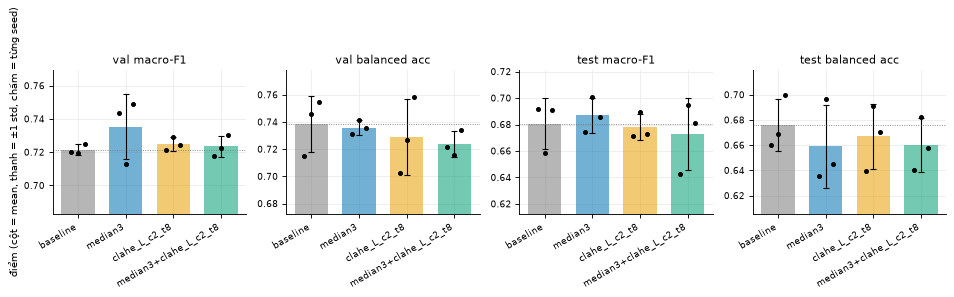

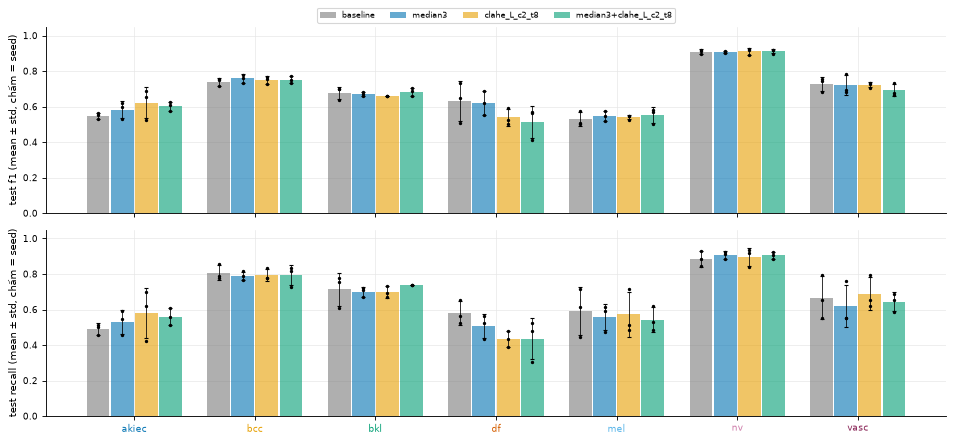

,config,recall_mel_mean,recall_mel_std,recall_mel_delta,recall_mel_delta_sign,recall_bcc_mean,recall_bcc_std,recall_bcc_delta,recall_bcc_delta_sign,recall_akiec_mean,recall_akiec_std,recall_akiec_delta,recall_akiec_delta_sign,f1_mel_mean,f1_mel_std,f1_mel_delta,f1_mel_delta_sign,f1_bcc_mean,f1_bcc_std,f1_bcc_delta,f1_bcc_delta_sign,f1_akiec_mean,f1_akiec_std,f1_akiec_delta,f1_akiec_delta_sign
0,baseline,0.592,0.136,NaN,NaN,0.806,0.042,NaN,NaN,0.490,0.032,NaN,NaN,0.530,0.042,NaN,NaN,0.740,0.022,NaN,NaN,0.549,0.016,NaN,NaN
1,median3,0.559,0.075,-0.033,1+/1-,0.790,0.024,-0.016,1+/2-,0.530,0.069,0.040,2+/1-,0.546,0.029,0.016,2+/1-,0.759,0.023,0.019,2+/1-,0.583,0.046,0.034,2+/1-
2,clahe_L_c2_t8,0.572,0.126,-0.020,2+/1-,0.796,0.034,-0.010,1+/1-,0.581,0.141,0.091,2+/1-,0.540,0.012,0.010,2+/1-,0.750,0.020,0.010,3+/0-,0.622,0.087,0.073,2+/1-
3,median3+clahe_L_c2_t8,0.544,0.071,-0.048,1+/2-,0.793,0.057,-0.013,1+/2-,0.561,0.045,0.071,3+/0-,0.551,0.044,0.022,1+/2-,0.752,0.020,0.012,2+/1-,0.602,0.026,0.053,3+/0-


In [18]:
NAMES = ["baseline"] + FULL
F_ = CMP.fig_overall(NAMES); plt.show()
F_ = CMP.fig_per_class(NAMES, "test"); plt.show()
F_ = CMP.fig_per_class(NAMES, "val"); plt.close("all")
rec = ["recall_mel", "recall_bcc", "recall_akiec", "f1_mel", "f1_bcc", "f1_akiec"]
display(cmp_test[["config"] + [f"{m}_{k}" for m in rec for k in ("mean", "std", "delta", "delta_sign")]].round(3))

**Hình P6.** Macro-F1 và balanced accuracy trên val và test (cột = mean, thanh = ±1 std, chấm = từng seed 42/43/44; đường chấm = mean baseline).
**Hình P7.** F1 (trên) và recall (dưới) từng lớp trên test, cùng quy ước; màu nhãn lớp theo bảng màu EDA. Bản val: `fig_p7_cnn_per_class_val`.
Lưu ý: val dùng để chọn epoch tốt nhất, nên số val lạc quan hơn test.

## H. Phân tích trên nhóm ảnh có vấn đề

Với mỗi ảnh, lỗi = tỉ lệ seed dự đoán sai (trung bình 3 seed). So sánh nhóm cờ (`F_noise`, `F_low_contrast` của EDA) với phần còn lại;
`err_rest_class_matched` = lỗi kỳ vọng nếu nhóm có cùng tỉ lệ lỗi **theo lớp** như phần còn lại (chuẩn hóa thành phần lớp), vì nhóm nhiễu
toàn `nv`, nhóm tương phản thấp nhiều `bcc/akiec/bkl`. `d_err_vs_baseline` = thay đổi lỗi so với baseline trên **cùng ảnh**, CI95 bootstrap cụm lesion.
Hạn chế: nhóm low_contrast dựa trên mask Otsu thô, ~40% mask sai trong mẫu kiểm tra (mục B.5); cỡ nhóm nhỏ (val 132/71, test 139/89 ảnh).

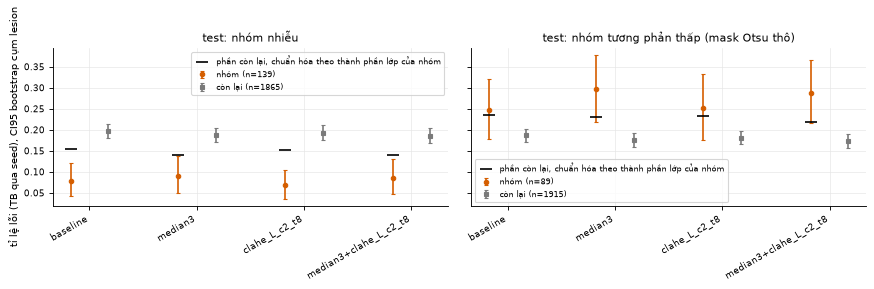

,config,split,flag,n_images,n_seeds,err,err_lo,err_hi,err_rest_class_matched,d_err_vs_baseline,d_lo,d_hi
0,baseline,val,F_noise,132,3,0.066,0.035,0.101,0.160,NaN,NaN,NaN
2,baseline,val,F_low_contrast,71,3,0.272,0.181,0.366,0.242,NaN,NaN,NaN
4,median3,val,F_noise,132,3,0.038,0.015,0.068,0.130,-0.028,-0.058,0.005
6,median3,val,F_low_contrast,71,3,0.268,0.176,0.367,0.232,-0.005,-0.069,0.064
8,clahe_L_c2_t8,val,F_noise,132,3,0.045,0.023,0.073,0.143,-0.020,-0.040,-0.003
10,clahe_L_c2_t8,val,F_low_contrast,71,3,0.258,0.169,0.348,0.234,-0.014,-0.075,0.048
12,median3+clahe_L_c2_t8,val,F_noise,132,3,0.048,0.025,0.076,0.137,-0.018,-0.040,0.005
14,median3+clahe_L_c2_t8,val,F_low_contrast,71,3,0.216,0.142,0.300,0.232,-0.056,-0.133,0.015
16,baseline,test,F_noise,139,3,0.079,0.043,0.120,0.155,NaN,NaN,NaN
18,baseline,test,F_low_contrast,89,3,0.247,0.178,0.322,0.236,NaN,NaN,NaN


In [19]:
SG = pd.concat([CMP.subgroup_errors(FULL, sp, flags) for sp in ("val", "test")], ignore_index=True)
SG.to_csv(OUT / "subgroup_errors.csv", index=False)
F_ = CMP.fig_subgroups(SG, "test"); plt.show()
F_ = CMP.fig_subgroups(SG, "val"); plt.close("all")
display(SG[SG.group == "nhóm"].drop(columns=["group"]).round(3))

**Hình P8.** Tỉ lệ lỗi trên test (trung bình 3 seed) của nhóm nhiễu (trái) và nhóm tương phản thấp (phải) so với phần còn lại, CI95 bootstrap cụm lesion;
gạch ngang đen = lỗi của phần còn lại sau khi chuẩn hóa theo thành phần lớp của nhóm. Bản val: `fig_p8_subgroup_error_val`.

## I. Nhận xét chung

*(Mọi số trích từ `comparison_{val,test}.csv`, `screening_val_seed42.csv`, `subgroup_errors.csv`; mean ± std qua 3 seed 42/43/44; CI = bootstrap cụm lesion, 1000 lần.)*

**Sàng lọc (mục F).** Val macro-F1 của seed 42: `median3` 0.7437 > `gauss3` 0.7048; `clahe_L_c2_t8` 0.7211 > `stretch_L_1_99` 0.6898 (baseline seed 42: 0.7201).
Cả hai chênh lệch đều lớn hơn std val của baseline (0.0032), nên quy tắc chọn trả về `median3` và `clahe_L_c2_t8`, không cần tie-break.
Hiệu ứng "người thắng" hiện rõ: `median3` đạt 0.7437 ở seed 42 nhưng mean 3 seed chỉ là 0.7353 ± 0.0196, trong đó seed 43 là 0.7129, thấp hơn baseline.
Điều này cho thấy sàng lọc 1 seed trên val không đáng tin để kết luận.

**So sánh 3 seed (Hình P6, P7).**

| Cấu hình | val macro-F1 | test macro-F1 | Δ test (CI95) | test balanced acc | Δ test bAcc (CI95) | Kết luận |
|---|---|---|---|---|---|---|
| baseline | 0.7215 ± 0.0032 | 0.6805 ± 0.0192 | – | 0.6761 ± 0.0206 | – | – |
| `median3` | 0.7353 ± 0.0196 | 0.6870 ± 0.0133 | +0.0065 (−0.017; 0.033), 1+/2− | 0.6591 ± 0.0332 | −0.0171 (−0.038; 0.008) | không khác biệt rõ |
| `clahe_L_c2_t8` | 0.7248 ± 0.0041 | 0.6779 ± 0.0099 | −0.0026 (−0.029; 0.026), 1+/2− | 0.6670 ± 0.0260 | −0.0091 (−0.036; 0.019) | không khác biệt rõ |
| `median3+clahe_L_c2_t8` | 0.7236 ± 0.0064 | 0.6728 ± 0.0273 | −0.0077 (−0.035; 0.022), 1+/2− | 0.6602 ± 0.0214 | −0.0159 (−0.045; 0.016) | không khác biệt rõ |

- Trên val và test, cho cả macro-F1 lẫn balanced accuracy, mọi Δ đều nhỏ hơn hoặc xấp xỉ dao động giữa seed của baseline (std test 0.019–0.021), mọi CI95 đều chứa 0, và không cấu hình nào có 3/3 cặp seed cùng dấu → **không khác biệt rõ** so với baseline.
- Balanced accuracy trên test có Δ âm ở cả 3 cấu hình (−0.009 đến −0.017). Xu hướng này nhất quán về dấu nhưng nằm trong nhiễu, nên chỉ ghi nhận, không kết luận.
- **Theo lớp, trên test** (chỉ là quan sát; mỗi lớp nhỏ nên rất nhiễu):
  - **akiec**: recall tăng ở cả 3 cấu hình (+0.040 / +0.091 / +0.071). Tuy vậy std giữa seed lớn (CLAHE: 0.141), và chỉ phép kết hợp có 3/3 seed cùng dấu. Test chỉ có 66 ảnh akiec.
  - **mel**: recall giảm (−0.02 đến −0.05) nhưng nằm trong std của baseline (0.136).
  - **bcc**: recall gần như không đổi (−0.01 đến −0.02).
  - **df**: recall giảm ở cả 3 cấu hình (−0.07 / −0.145 / −0.145), CLAHE và kết hợp có 0+/3−. Nhưng test chỉ có 23 ảnh df (1 ảnh ≈ 0.043), nên đây là tín hiệu cần kiểm tra chứ chưa phải kết luận.
- **Các cấu hình chỉ chạy 1 seed** (không kết luận, xem ô bảng 1 seed ở mục G):
  - `stretch_L_1_99` và `hist_eq_L` có val macro-F1 thấp hơn baseline seed 42 lần lượt 0.030 và 0.044, lớn hơn nhiều so với std val. Điều này khớp với dự đoán của H-C rằng phương pháp toàn cục, vốn biến đổi mạnh cả ảnh bình thường (ΔE 14–22), có hại.
  - `median5` có val 0.7215, gần baseline.

**Theo nhóm ảnh (Hình P8, `subgroup_errors.csv`).**
- **Baseline, nhóm nhiễu:** tỉ lệ lỗi **thấp hơn** phần còn lại (test 0.079, CI 0.043–0.120), kể cả khi so với mức kỳ vọng sau chuẩn hóa thành phần lớp (0.155). Diễn giải thận trọng: nhóm này chủ yếu là ảnh `nv` `follow_up`, một nguồn ảnh "dễ". Kết quả này phù hợp với giả thuyết shortcut thiết bị nhưng chưa chứng minh được nó.
- **Khử nhiễu và nhóm nhiễu:** khử nhiễu không làm thay đổi rõ lỗi của nhóm này. Trên test, Δ lỗi so với baseline là +0.012 (−0.014; 0.038) với `median3`. Trên val, Δ là −0.028 (−0.058; 0.005). Hai split ngược dấu, đều nằm trong nhiễu.
- **Baseline, nhóm tương phản thấp:** lỗi 0.247 (test), xấp xỉ mức kỳ vọng sau chuẩn hóa lớp (0.236). Như vậy lỗi cao hơn của nhóm này chủ yếu do thành phần lớp (nhiều bcc/akiec/bkl), chưa thấy "tương phản thấp" tự nó gắn với thêm lỗi.
- **CLAHE và nhóm tương phản thấp:** CLAHE không làm giảm lỗi của nhóm này (test Δ +0.004, CI −0.053; 0.055).
- **Kết hợp và nhóm tương phản thấp:** Δ là +0.041 (test) và −0.056 (val), ngược dấu giữa hai split.
- **Hạn chế:** nhóm nhỏ (val 132/71, test 139/89 ảnh). Nhóm tương phản thấp dựa trên mask Otsu thô, trong mẫu kiểm tra có khoảng 40% mask sai (B.5).

**Kết luận theo giả thuyết.**
- **H-N (khử nhiễu không cải thiện rõ):** **được ủng hộ.** `median3` không khác biệt rõ so với baseline (test macro-F1 Δ +0.0065, CI chứa 0). Điều này khớp với phân tích ảnh: sau resize 224 chỉ còn khoảng 0.3 mức xám nhiễu để lọc. Phần "lọc 5×5 có thể làm giảm" chưa kiểm chứng được, vì `median5` chỉ chạy 1 seed và val gần baseline.
- **H-C (tăng tương phản không cải thiện rõ macro-F1; phương pháp toàn cục rủi ro hơn):**
  - Vế đầu **được ủng hộ**: CLAHE không khác biệt rõ.
  - Vế sau **được gợi ý** qua sàng lọc 1 seed: stretch và hist_eq có val thấp hơn baseline. Chưa có 3 seed nên chưa phải kết luận.
- **Kết hợp** (`median3` → CLAHE): không khác biệt rõ so với baseline, cũng không tốt hơn từng thành phần.
- **Đề xuất cho pipeline (2.6):** chưa có bằng chứng để đưa khử nhiễu hay tăng tương phản vào pipeline cuối vì lý do hiệu năng. Nếu nhóm vẫn muốn giữ một bước vì mục đích hiển thị/demo, CLAHE trên L\* với clip 2 là lựa chọn ít rủi ro nhất: Δ ≈ 0, std giữa seed nhỏ nhất, giữ màu (Δab 0.23). Cần ghi rõ đây là lựa chọn "không hại", không phải "có lợi".
- **Tính tái lập:** huấn luyện dùng AMP + `cudnn.benchmark` nên không tất định từng bit. Các so sánh trên đã dựa trên dao động giữa seed, bao gồm cả nguồn này. Test chỉ được đọc sau khi đã chốt cấu hình bằng val.